<a href="https://colab.research.google.com/github/samarjeet621/Machine_Learning_Project/blob/Develop/Deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### MNIST Handwriting Classification: Step-by-Step Explanation

This notebook demonstrates how to train a basic single-layer neural network using **TensorFlow** and **Keras** to classify handwritten digits (0-9) from the classic **MNIST dataset**.

---

#### Step 1: Library Imports
```python
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
```
* **`tensorflow` & `keras`**: The core frameworks used for building, compiling, and training the deep learning model.
* **`matplotlib.pyplot`**: Used to visualize the handwritten images.
* **`numpy`**: Used for efficient numerical and array-based operations (like extracting maximum confidence scores).

---

#### Step 2: Loading the Dataset
```python
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
```
* **`keras.datasets.mnist.load_data()`**: Downloads and splits the MNIST dataset into:
  * **`x_train`, `y_train`**: 60,000 images and corresponding labels (0-9) used to train the model.
  * **`x_test`, `y_test`**: 10,000 images and corresponding labels used to evaluate how well the model generalizes to unseen data.

---

#### Step 3: Feature Scaling (Normalization)
```python
x_train = x_train / 255
x_test = x_test / 255
```
* **Purpose**: Raw image pixel values range from `0` (black) to `255` (white). Dividing by `255.0` scales these values to a range between `0.0` and `1.0`. Scaling improves optimization convergence and speeds up training.

---

#### Step 4: Flattening the Images
```python
x_train_flattened = x_train.reshape(len(x_train), 28*28)
x_test_flattened = x_test.reshape(len(x_test), 28*28)
```
* **`reshape`**: Since our neural network expects a 1D vector of features for each image, we transform each 2D image of shape `(28, 28)` into a 1D array of `784` elements (`28 * 28 = 784`).

---

#### Step 5: Building and Training the Model
```python
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(x_train_flattened, y_train, epochs=5)
```
* **`keras.Sequential`**: Groups a linear stack of layers.
* **`layers.Dense(10, ...)`**: A fully connected (dense) layer with `10` output units (representing the digits 0 through 9).
* **`activation='sigmoid'`**: Squashes outputs between `0` and `1` (commonly used here to output probabilities/activations for each class).
* **`optimizer='adam'`**: An adaptive learning rate optimization algorithm used to update network weights.
* **`loss='sparse_categorical_crossentropy'`**: The loss function used for multi-class classification when target labels are integers (like `0, 1, 2...9`) rather than one-hot encoded vectors.
* **`epochs=5`**: The number of times the network goes through the entire training dataset.

---

#### Step 6: Model Evaluation
```python
model.evaluate(x_test_flattened, y_test)
```
* **`model.evaluate()`**: Calculates the final loss value and metric values (accuracy) on your testing set to see how well the model performs on images it has never seen during training.

---

#### Step 7: Prediction and Argmax
```python
y_predicted = model.predict(x_test_flattened)
np.argmax(y_predicted[0])
```
* **`model.predict()`**: Generates output predictions (probabilities) for the testing samples.
* **`np.argmax()`**: Since `y_predicted[0]` outputs 10 probability scores (one for each class), `np.argmax` returns the index of the highest probability score, which represents the model's final digit prediction.

In [2]:
from ast import increment_lineno
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
len(x_train)

60000

In [5]:
len(x_test)

10000

In [6]:
x_train[0].shape

(28, 28)

In [7]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

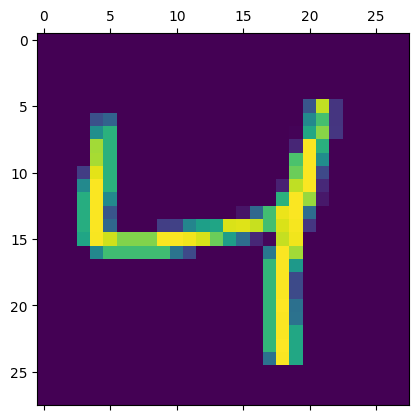

In [8]:
# plt.matshow(x_train[0])
plt.matshow(x_train[2])

In [9]:
y_train[2]

np.uint8(4)

In [10]:
x_train = x_train/255
x_test = x_test/255

In [11]:
x_train_flattened = x_train.reshape(len(x_train),28*28)
x_test_flattened = x_test.reshape(len(x_test), 28*28)

In [12]:
x_test_flattened.shape

(10000, 784)

In [13]:
x_train_flattened[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [14]:
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,),activation='sigmoid')
    ])

model.compile(
    optimizer='adam',
    loss = 'sparse_categorical_crossentropy',
    metrics=['accuracy']
    )
model.fit(x_train_flattened, y_train, epochs=5)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8764 - loss: 0.4700
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9160 - loss: 0.3039
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9204 - loss: 0.2831
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9232 - loss: 0.2736
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9261 - loss: 0.2668


In [15]:
# Evaluate the model's performance on unseen test data
# This returns the loss value and the metrics (accuracy) defined during compilation
model.evaluate(x_test_flattened, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9254 - loss: 0.2681


[0.26810890436172485, 0.9254000186920166]

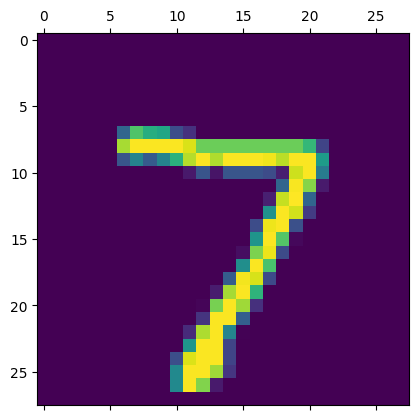

In [16]:
plt.matshow(x_test[0])

In [17]:
# Generate prediction probabilities for all test images
y_predicted = model.predict(x_test_flattened)

# Look at the 10 output class probabilities for the first test image
y_predicted[0]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([2.1195440e-02, 4.5490270e-07, 7.2599910e-02, 9.6531355e-01,
       2.1011375e-03, 1.2406428e-01, 1.8200997e-06, 9.9975473e-01,
       1.0753628e-01, 7.2224849e-01], dtype=float32)

In [18]:
# Get the index of the maximum probability value, which is the predicted digit
np.argmax(y_predicted[0])

np.int64(7)

In [19]:
# Extract the predicted class labels for all prediction arrays
y_predicted_labels = [np.argmax(i) for i in y_predicted]

# Preview the first 5 predicted digit labels
y_predicted_labels[:5]

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4)]

In [21]:
# Preview the actual ground truth labels for the first 5 test images to compare
y_test[:5]

array([7, 2, 1, 0, 4], dtype=uint8)

In [23]:
# Compute a confusion matrix to evaluate classification accuracy across all 10 digits
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_predicted_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 961,    0,    1,    2,    0,    5,    7,    2,    1,    1],
       [   0, 1118,    3,    2,    0,    1,    4,    2,    5,    0],
       [   8,    9,  923,   16,    7,    5,   13,    9,   37,    5],
       [   3,    0,   17,  923,    0,   22,    2,   11,   22,   10],
       [   1,    2,    3,    2,  900,    0,   13,    4,    8,   49],
       [  10,    2,    2,   33,    8,  775,   18,    6,   32,    6],
       [  10,    3,    6,    1,    7,   11,  916,    2,    2,    0],
       [   1,    6,   24,    9,    7,    1,    0,  935,    2,   43],
       [   8,   10,    7,   22,    8,   27,   10,    8,  860,   14],
       [  11,    7,    1,    9,   14,    6,    0,   13,    5,  943]],
      dtype=int32)>

Text(95.72222222222221, 0.5, 'Truth')

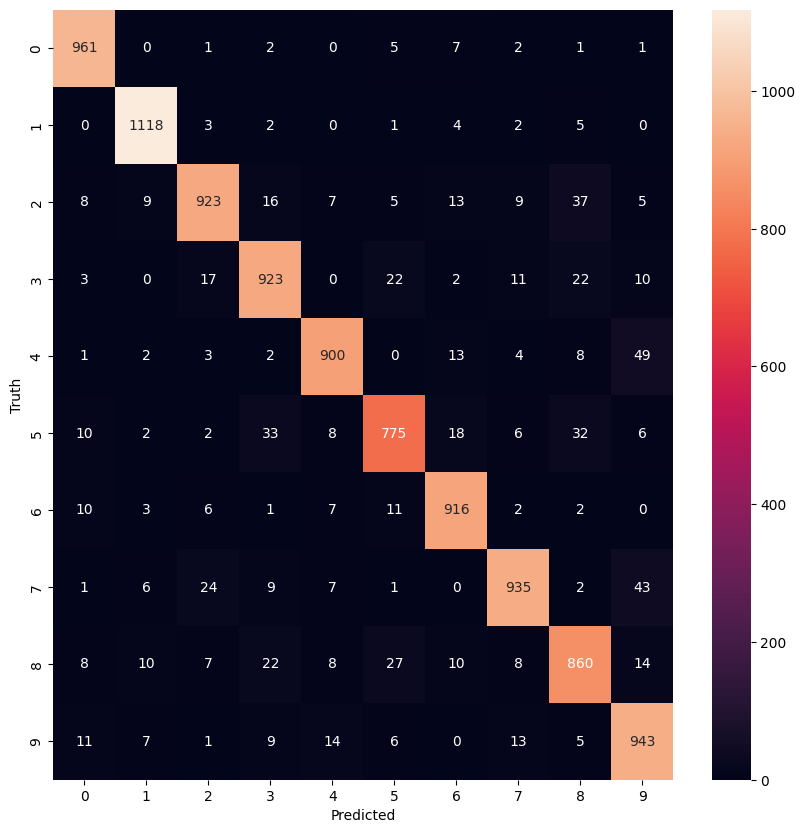

In [24]:
import seaborn as sn

# Visualize the confusion matrix using a heatmap for better readability
plt.figure(figsize=(10,10))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

In [25]:
# Build an improved model containing a hidden layer with 100 neurons
model = keras.Sequential([
    # Hidden layer: Dense layer with 100 units using ReLU activation
    keras.layers.Dense(100, input_shape=(784,), activation='relu'),
    # Output layer: Dense layer with 10 units using Sigmoid activation
    keras.layers.Dense(10, activation='sigmoid')
])

# Compile the network
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Fit the model with the training data over 5 epochs
model.fit(x_train_flattened, y_train, epochs=5)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9215 - loss: 0.2739
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9638 - loss: 0.1223
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9748 - loss: 0.0852
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9804 - loss: 0.0644
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9844 - loss: 0.0495


In [26]:
model.evaluate(x_test_flattened, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9792 - loss: 0.0702


[0.07019996643066406, 0.979200005531311]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


Text(95.72222222222221, 0.5, 'Truth')

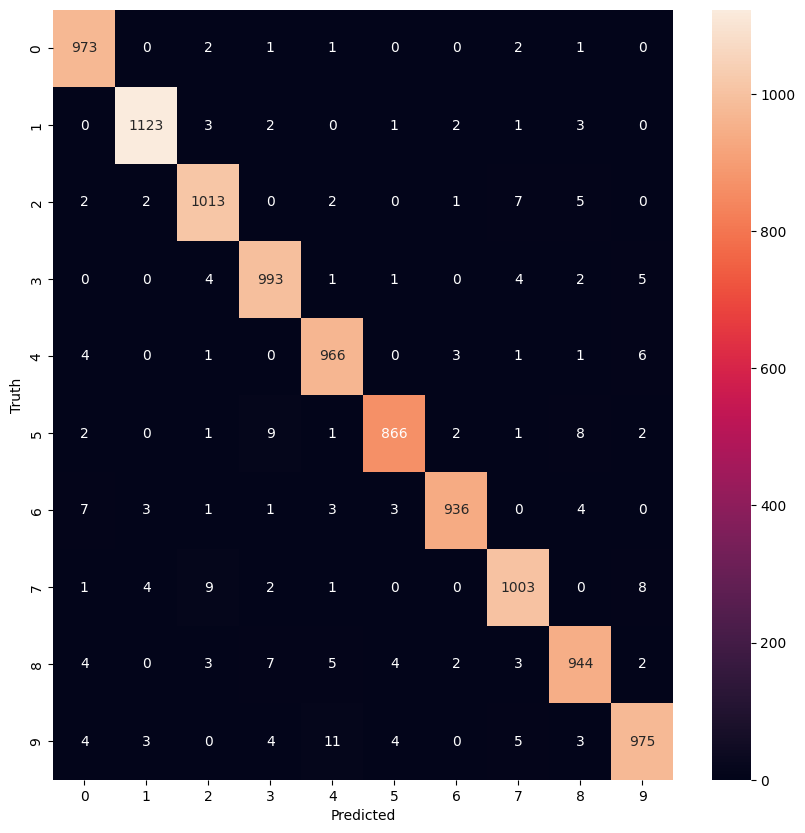

In [27]:
# Generate predictions using the improved neural network model with a hidden layer
y_predicted = model.predict(x_test_flattened)
y_predicted_labels = [np.argmax(i) for i in y_predicted]

# Compute the updated confusion matrix
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_predicted_labels)

# Plot the updated confusion matrix heatmap
import seaborn as sn
plt.figure(figsize=(10,10))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

In [29]:
# Build the final model utilizing Keras' Flatten layer directly
# This eliminates the need to manually reshape/flatten the 2D image arrays beforehand
model = keras.Sequential([
    # Automatically flattens 2D inputs of shape (28, 28) into 1D inputs of shape (784,)
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model using the original 2D x_train dataset directly
model.fit(x_train, y_train, epochs=5)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9229 - loss: 0.2710
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9633 - loss: 0.1237
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9743 - loss: 0.0860
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9804 - loss: 0.0647
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9839 - loss: 0.0522
